In [2]:
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append("..")
from he_time_evolution import *

inches_per_pt = 1 / 72.27
gr = (np.sqrt(5) - 1) / 2
tex_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    "font.family": "cmr",
    # Use 10pt font in plots, to match 10pt font in document
    "axes.labelsize": 10,
    "font.size": 10,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "text.latex.preamble": r"\usepackage[OT1]{fontenc}\usepackage{physics}"
}
plt.rcParams.update(tex_fonts)

In [11]:
# params = "beta"
# config = "II"
# sigma = 0.09
# t_hold = 0.60
# t_hold_min = 0
# t_hold_max = 5.0


# params = "zz_II"
# config = "II"
# sigma = 0.25
# t_hold = 0.10
# t_hold_min = 0
# t_hold_max = 5.0

params = "beta"
config = "III"
sigma = 0.55
t_hold = 3.20
t_hold_min = 0.0
t_hold_max = 5.0

# params = "zz_III"
# config = "III"
# sigma = 0.23
# t_hold = 8.3
# t_hold_min = 0
# t_hold_max = 10

t_step = 0.1
opt_params = {"beta_II": [0.09, 0.60, 0, 5], "zz_II": [0.25, 0.10, 0, 5], "beta_III": [0.55, 3.20, 0, 5], "zz_III": [0.23, 8.3, 0, 10]}

dir = f"{params}_params/hold_sweep/config_{config}/{t_hold_min:.2f}-{t_hold_max:.2f}-{t_step:.2f}_sigma_{sigma:.2f}"

In [12]:
dt = (0.001*ureg.ns/time_unit).to(ureg.dimensionless).magnitude
t_0_ind = int(((t_hold_min + 4*np.sqrt(2) * sigma)* ureg.ns / time_unit).to(ureg.dimensionless).magnitude/dt) - 100
t_max = (t_hold_max + 2*4*np.sqrt(2) * sigma)


num_states = 6
hold_times = np.arange(t_hold_min, t_hold_max + 0.005*t_step, t_step)

In [13]:
def plot(axs, time_points, overlaps):
    plts = []
    for i in range(4):
        axs[i].set_prop_cycle(None)
        for j in range(num_states):
            
            p0, = axs[i].plot( #axs[i, 0].plot(
                (time_points[:, i] * time_unit).to(ureg.ns).magnitude,
                np.abs(overlaps[:, j, i]) ** 2,
                label=r"$|\langle \Phi_{"
                + str(i if i != 3 else 4)
                + r"}(t)| \Phi_{"
                + str(j)
                + r"}\rangle|^2$",
            )
            plts.append(p0)
            
    return plts

In [14]:
# Load the first dataset

time_points, energies, overlaps, _ = np.load(dir + f"/t_hold_{hold_times[0]:.2f}.npz").values()

t_full = time_points[:t_0_ind]
e_full = energies[:t_0_ind]
o_full = overlaps[:t_0_ind]

n_new_pts = int(((t_step*ureg.ns/time_unit).to(ureg.dimensionless).magnitude)/dt)

for i, t in enumerate(hold_times[1:]):
    time_points, energies, overlaps, _ = np.load(dir + f"/t_hold_{t:.2f}.npz").values()
    t_full = np.concatenate((t_full, time_points[:n_new_pts]))
    e_full = np.concatenate((e_full, energies[:n_new_pts]))
    o_full = np.concatenate((o_full, overlaps[:n_new_pts]))

t_full = (t_full * time_unit).to(ureg.ns).magnitude
o_full = np.abs(o_full) ** 2
e_full = e_full.real * energy_frequency.magnitude

In [15]:
# Load a second dataset for comparison
# You can change these parameters to point to another dataset
# params2 = "zz_II"
# config2 = "II"
# sigma2 = 0.25
# t_hold2 = 0.10
# t_hold_min2 = 0
# t_hold_max2 = 5.0
# t_step2 = 0.1

params2 = "zz_III"
config2 = "III"
sigma2 = 0.23
t_hold2 = 8.3
t_hold_min2 = 0
t_hold_max2 = 10
t_step2 = 0.1




dir2 = f"{params2}_params/hold_sweep/config_{config2}/{t_hold_min2:.2f}-{t_hold_max2:.2f}-{t_step2:.2f}_sigma_{sigma2:.2f}"

dt2 = (0.001*ureg.ns/time_unit).to(ureg.dimensionless).magnitude
t_0_ind2 = int(((t_hold_min2 + 4*np.sqrt(2) * sigma2 + 0.01)* ureg.ns / time_unit).to(ureg.dimensionless).magnitude/dt2) - 100
t_max2 = (t_hold_max2 + 2*4*np.sqrt(2) * sigma2)
hold_times2 = np.arange(t_hold_min2, t_hold_max2 + 0.1*t_step2, t_step2)

time_points2, energies2, overlaps2, _ = np.load(dir2 + f"/t_hold_{hold_times2[0]:.2f}.npz").values()
t_full2 = time_points2[:t_0_ind2]
e_full2 = energies2[:t_0_ind2]
o_full2 = overlaps2[:t_0_ind2]
n_new_pts2 = int(((t_step2*ureg.ns/time_unit).to(ureg.dimensionless).magnitude)/dt2)
for i, t in enumerate(hold_times2[1:]):
    time_points2, energies2, overlaps2, _ = np.load(dir2 + f"/t_hold_{t:.2f}.npz").values()
    t_full2 = np.concatenate((t_full2, time_points2[:n_new_pts2]))
    e_full2 = np.concatenate((e_full2, energies2[:n_new_pts2]))
    o_full2 = np.concatenate((o_full2, overlaps2[:n_new_pts2]))
t_full2 = (t_full2 * time_unit).to(ureg.ns).magnitude
o_full2 = np.abs(o_full2) ** 2
e_full2 = e_full2.real * energy_frequency.magnitude

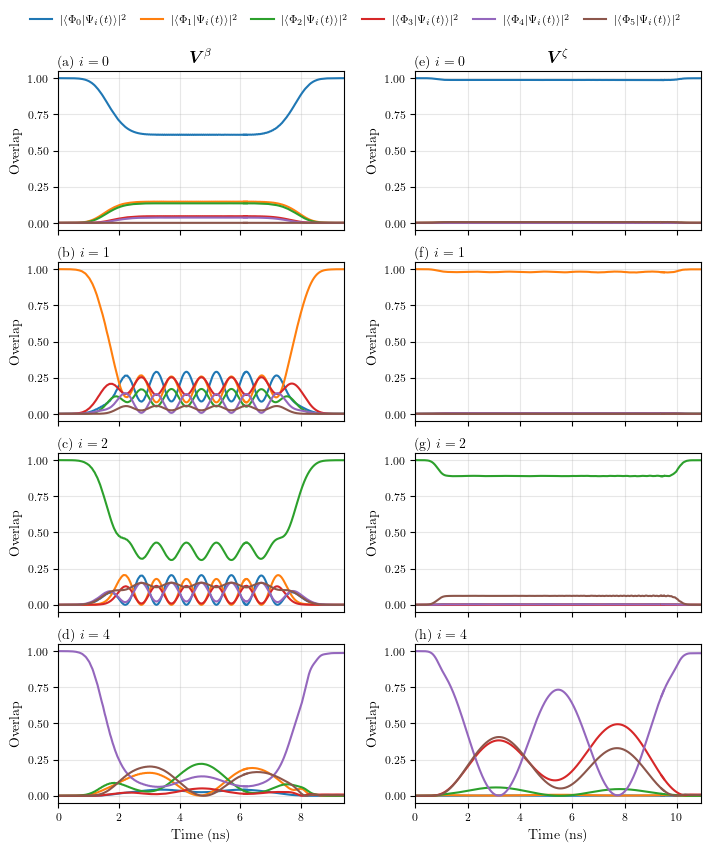

In [16]:

# Prepare the figure with two columns
fig, axs = plt.subplots(
    nrows=4,
    ncols=2,
    sharex='col',
    figsize=(510*inches_per_pt, 4*246*gr*inches_per_pt),
)

labels = ["(a) $i=0$", "(b) $i=1$", "(c) $i=2$", "(d) $i=4$", "(e) $i=0$", "(f) $i=1$", "(g) $i=2$", "(h) $i=4$"]
for i in range(4):
    axs[i, 0].set_xlim(0, t_hold + 2*4*np.sqrt(2) * sigma)
    axs[i, 1].set_xlim(0, t_hold2 + 2*4*np.sqrt(2) * sigma2)
    for col in range(2):
        axs[i, col].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[i, col].set_ylabel("Overlap")
        axs[i, col].grid(alpha=0.3)
        axs[i, col].text(0.0, 1.01, labels[i + 4*col], transform=axs[i, col].transAxes, ha='left', va="bottom")

axs[-1, 0].set_xlabel("Time (ns)")
axs[-1, 1].set_xlabel("Time (ns)")
axs[0, 0].set_title(r"$\vb*{V}^\beta$")
axs[0, 1].set_title(r"$\vb*{V}^\zeta$")

# Plot for first dataset (left column)
plts1 = plot(axs[:, 0], t_full[:t_0_ind], o_full[:t_0_ind])
time_points, energies, overlaps, _ = np.load(dir + f"/t_hold_{hold_times[0]:.2f}.npz").values()
for p in plot(axs[:, 0], time_points[t_0_ind:], overlaps[t_0_ind:]):
    plts1.append(p)
# Plot for second dataset (right column)
plts2 = plot(axs[:, 1], t_full2[:t_0_ind2], o_full2[:t_0_ind2])
time_points2, energies2, overlaps2, _ = np.load(dir2 + f"/t_hold_{hold_times2[0]:.2f}.npz").values()
for p in plot(axs[:, 1], time_points2[t_0_ind2:], overlaps2[t_0_ind2:]):
    plts2.append(p)

# First dataset (left column)
ind1 = np.argmin(np.abs(hold_times - t_hold))
end = t_0_ind + ind1*n_new_pts
k = 0
for i in range(4):
    for j in range(num_states):
        plts1[k].set_xdata(t_full[:end, i])
        plts1[k].set_ydata(o_full[:end, j, i])
        k += 1
time_points, _, overlaps, _ = np.load(dir + f"/t_hold_{hold_times[ind1]:.2f}.npz").values()
for i in range(4):
    for j in range(num_states):
        plts1[k].set_xdata((time_points[:, i] * time_unit).to(ureg.ns).magnitude)
        plts1[k].set_ydata(np.abs(overlaps[:, j, i]) ** 2)
        k += 1
# Second dataset (right column)
ind2 = np.argmin(np.abs(hold_times2 - t_hold2))
end2 = t_0_ind2 + ind2*n_new_pts2
k2 = 0
for i in range(4):
    for j in range(num_states):
        plts2[k2].set_xdata(t_full2[:end2, i])
        plts2[k2].set_ydata(o_full2[:end2, j, i])
        k2 += 1
time_points2, _, overlaps2, _ = np.load(dir2 + f"/t_hold_{hold_times2[ind2]:.2f}.npz").values()
for i in range(4):
    for j in range(num_states):
        plts2[k2].set_xdata((time_points2[:, i] * time_unit).to(ureg.ns).magnitude)
        plts2[k2].set_ydata(np.abs(overlaps2[:, j, i]) ** 2)
        k2 += 1


plt.subplots_adjust(top=0.92, left=0.08, bottom=0.05, right=0.99, wspace=0.25)
labels_legend = [rf"$|\langle \Phi_{{{j}}}|\Psi_i(t)\rangle|^2$" for j in range(num_states)]
handles, _ = axs[0, 0].get_legend_handles_labels()
fig.legend(handles[:num_states], labels_legend, loc='upper center', ncol=6, bbox_to_anchor=(0.5, 1.0), columnspacing=1.3, frameon=False)

#fig.savefig("figs/opt_swap_evolution.pdf")
fig.savefig("figs/opt_cz_evolution.pdf")

plt.show()

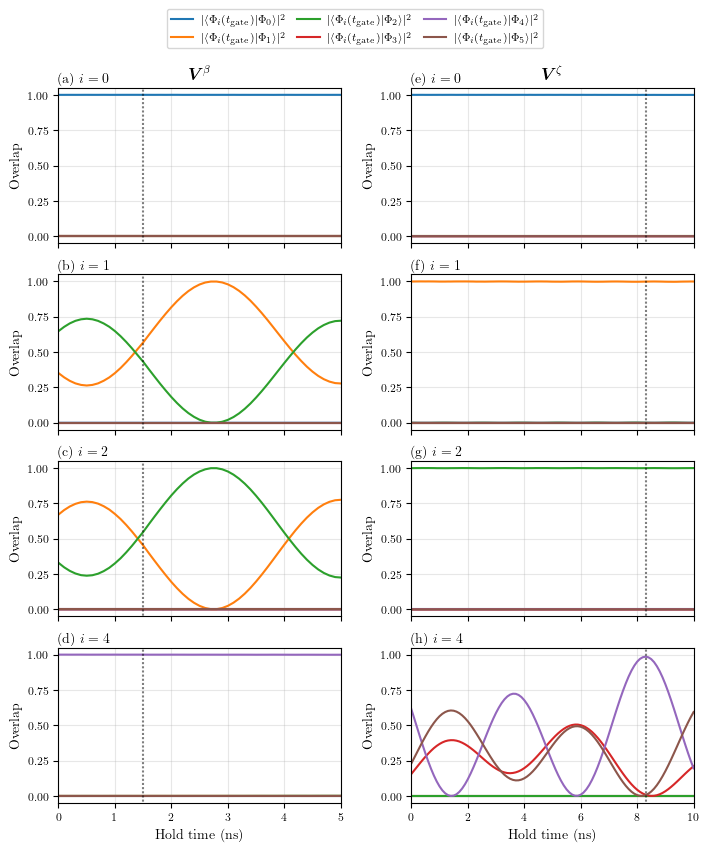

In [9]:
# Load a second dataset for comparison
# You can change these parameters to point to another dataset
# params2 = "zz_II"
# config2 = "II"
# sigma2 = 0.25
# t_hold2 = 0.10
# t_hold_min2 = 0
# t_hold_max2 = 5.0
# t_step2 = 0.1

params2 = "zz_III"
config2 = "III"
sigma2 = 0.23
t_hold2 = 8.3
t_hold_min2 = 0
t_hold_max2 = 10
t_step2 = 0.1

dir2 = f"{params2}_params/hold_sweep/config_{config2}/{t_hold_min2:.2f}-{t_hold_max2:.2f}-{t_step2:.2f}_sigma_{sigma2:.2f}"

hold_times = np.arange(t_hold_min, t_hold_max + 0.1*t_step, t_step)
hold_times2 = np.arange(t_hold_min2, t_hold_max2 + 0.1*t_step2, t_step2)

o_final = np.zeros((len(hold_times), num_states, 4), dtype=complex)
o_final2 = np.zeros((len(hold_times2), num_states, 4), dtype=complex)

for i, t in enumerate(hold_times):
    _, _, overlaps, _ = np.load(dir + f"/t_hold_{t:.2f}.npz").values()
    o_final[i] = overlaps[-1]

for i, t in enumerate(hold_times2):
    _, _, overlaps2, _ = np.load(dir2 + f"/t_hold_{t:.2f}.npz").values()
    o_final2[i] = overlaps2[-1]

fig, axs = plt.subplots(
    nrows=4,
    ncols=2,
    sharex='col',
    #sharey='row',
    figsize=(510*inches_per_pt, 4*246*gr*inches_per_pt),
)

axs[0, 0].set_title(r"$\vb*{V}^\beta$")
axs[0, 1].set_title(r"$\vb*{V}^\zeta$")

labels = ["(a) $i=0$", "(b) $i=1$", "(c) $i=2$", "(d) $i=4$", "(e) $i=0$", "(f) $i=1$", "(g) $i=2$", "(h) $i=4$"]
for i in range(4):
    axs[i, 0].set_xlim(0, t_hold_max)
    axs[i, 1].set_xlim(0, t_hold_max2)
    axs[i, 0].set_ylim(-0.05, 1.05)
    axs[i, 1].set_ylim(-0.05, 1.05)

    axs[i, 0].plot(hold_times, np.abs(o_final[:, :, i])**2, label="beta")
    axs[i, 1].plot(hold_times2, np.abs(o_final2[:, :, i])**2, label ="zeta")

    axs[i, 0].vlines(t_hold, -0.1, 1.1, color='k', ls=(0, (1, 1)), alpha=0.5)
    axs[i, 1].vlines(t_hold2, -0.1, 1.1, color='k', ls=(0, (1, 1)), alpha=0.5)

    for j in range(2):
        axs[i, j].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[i, j].set_ylabel("Overlap")
        axs[i, j].grid(alpha=0.3)
        axs[i, j].text(0.0, 1.01, labels[i + 4*j], transform=axs[i, j].transAxes, ha='left', va="bottom")

    
axs[-1, 0].set_xlabel("Hold time (ns)")
axs[-1,1].set_xlabel("Hold time (ns)")


plt.subplots_adjust(top=0.90, left=0.08, bottom=0.05, right=0.98, wspace=0.25)

labels_legend = [rf"$|\langle \Phi_i(t_\mathrm{{gate}})| \Phi_{{{j}}}\rangle|^2$" for j in range(num_states)]
handles, _ = axs[0, 0].get_legend_handles_labels()
fig.legend(handles[:num_states], labels_legend, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.0), columnspacing=1.0)


plt.show()

#fig.savefig("figs/opt_ramp_cz.pdf")

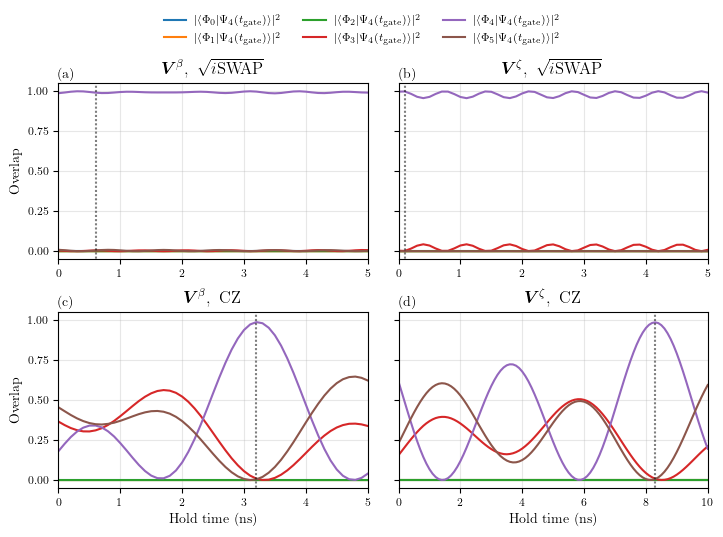

In [10]:
fig, axs = plt.subplots(
    nrows=2,
    ncols=2,
    sharey=True,
    figsize=(510*inches_per_pt, 380*inches_per_pt),
)

axs[0, 0].set_title(r"$\vb*{V}^\beta,~\sqrt{i\mathrm{SWAP}}$")
axs[0, 1].set_title(r"$\vb*{V}^\zeta,~\sqrt{i\mathrm{SWAP}}$")
axs[1, 0].set_title(r"$\vb*{V}^\beta,~\mathrm{CZ}$")
axs[1, 1].set_title(r"$\vb*{V}^\zeta,~\mathrm{CZ}$")

labels = ["(a)", "(b)", "(c)", "(d)"]

for i, config in enumerate(["II", "III"]):
    for j, params in enumerate(["beta", "zz"]):
        sigma, t_hold, t_hold_min, t_hold_max = opt_params[f"{params}_{config}"]
        dir = f"{params+"_"+config if params == "zz" else params}_params/hold_sweep/config_{config}/{t_hold_min:.2f}-{t_hold_max:.2f}-0.10_sigma_{sigma:.2f}"
        hold_times = np.arange(t_hold_min, t_hold_max + 0.1*t_step, t_step)
        o_final = np.zeros((len(hold_times), num_states, 4), dtype=complex)

        for k, t in enumerate(hold_times):
            _, _, overlaps, _ = np.load(dir + f"/t_hold_{t:.2f}.npz").values()
            o_final[k] = overlaps[-1]

        axs[i, j].plot(hold_times, np.abs(o_final[:, :, 3])**2, label=f"{params}, config {config}")
        axs[i, j].vlines(t_hold, -0.1, 1.1, color='k', ls=(0, (1, 1)), alpha=0.5)

        axs[i, j].set_xlim(0, t_hold_max)
        axs[i, j].set_ylim(-0.05, 1.05)
        axs[i, j].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[i, j].grid(alpha=0.3)
        axs[i, j].text(0.0, 1.01, labels[2*i + j], transform=axs[i, j].transAxes, ha='left', va="bottom")


    axs[i, 0].set_ylabel("Overlap")
    axs[-1, i].set_xlabel("Hold time (ns)")
    #axs[i, 0].text(-0.2, 0.5, "Test", transform=axs[i, 0].transAxes, ha='center', va="center", rotation = "vertical", fontsize=12, fontweight='bold')

plt.subplots_adjust(top=0.85, left=0.07, bottom=0.08, right=0.99, wspace=0.1, hspace=0.3)

labels_legend = [rf"$|\langle \Phi_{{{j}}}| \Psi_4(t_\mathrm{{gate}})\rangle|^2$" for j in range(num_states)]
handles, _ = axs[0, 0].get_legend_handles_labels()
fig.legend(handles[:num_states], labels_legend, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.0), frameon=False)#, columnspacing=1.0)

plt.show()

fig.savefig("figs/opt_ramp_33.pdf")